## 1. Import Libraries & Load Data

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import joblib
import pandas as pd

In [6]:
X_train, X_val, X_test, y_train, y_val, y_test = pd.read_csv('data/X_train_pre.csv'), pd.read_csv('data/X_val_pre.csv'), pd.read_csv('data/X_test_pre.csv'), pd.read_csv('data/y_train.csv'), pd.read_csv('data/y_val.csv'), pd.read_csv('data/y_test.csv')

## 2. Build Pipeline & Hyperparameter Tuning (`GridSearchCV`)

In [7]:
knn = KNeighborsRegressor()
# Hyperparameter tuning for k
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25, 30]
}

gscv = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

gscv.fit(X_train, y_train)
print("Best Parameters:", gscv.best_params_)
print("Best RMSE Score:", -gscv.best_score_)

Best Parameters: {'n_neighbors': 7}
Best RMSE Score: 6173.249253958233


## 3. Model Evaluation

In [8]:
best_model = gscv.best_estimator_
y_pred = best_model.predict(X_test)

# Evaluation metrics
print(f"Root Mean Square Error: {root_mean_squared_error(y_test, y_pred)}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")
print(f"R²: {r2_score(y_test, y_pred)}")

Root Mean Square Error: 6213.401405213836
Mean Absolute Error: 3909.5431213027714
R²: 0.7737784321796608


## 4. Predicted vs. Actual Plot

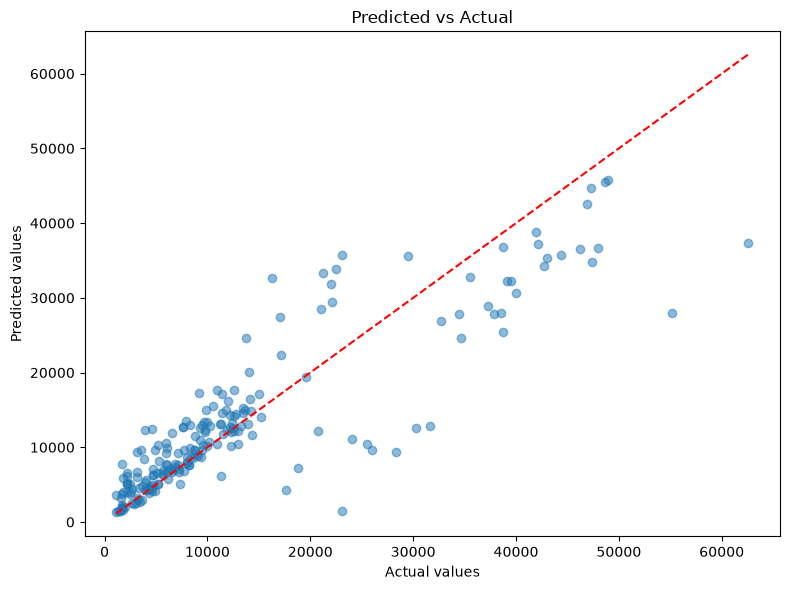

In [9]:
# Prediction vs Actual PLOT
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction line (pred = actual)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Predicted vs Actual")
plt.tight_layout()
plt.show()

## 5. Save Best Model

In [10]:
joblib.dump(knn, '../models/knn_regressor.pkl')

['../models/knn_regressor.pkl']